# Image classification through graph message passing

Can pixels represented as graph nodes support a trainable classifier?

I construct an eight-by-eight grid graph and implement normalized graph convolution directly with PyTorch. The image graph is a controlled adaptation of the message-passing ideas in ML4HD's audio graph laboratory.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "07_graph_message_passing"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Nodes, positions and edges

Each pixel is a node with intensity and two fixed coordinates. Four-neighbor edges plus self-loops define $\tilde A$. I use $D^{-1/2}\tilde A D^{-1/2}$ to normalize aggregation. This is an undirected grid, not the original audio MFCC graph.

torch.Size([64, 64]) nonzero entries: 288


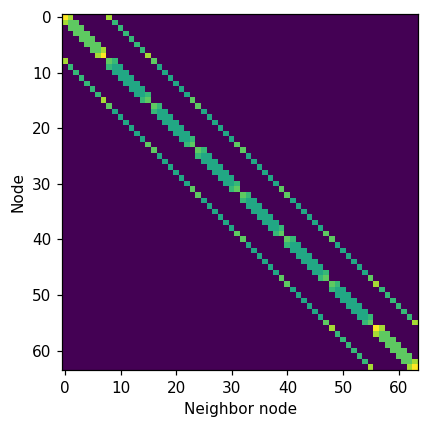

In [5]:
from deep_projects.models import GridGCN, grid_adjacency

data = digits_data(8)
train_loader, validation_loader, test_loader = data.loaders()
adjacency = grid_adjacency(8)
assert torch.equal(adjacency, adjacency.T)
assert torch.all(adjacency.diag() > 0)
print(adjacency.shape, "nonzero entries:", int((adjacency > 0).sum()))
plt.figure(figsize=(5, 4))
plt.imshow(adjacency, cmap="viridis")
plt.xlabel("Neighbor node")
plt.ylabel("Node")
plt.tight_layout()
plt.savefig(output / "adjacency.png", dpi=140)
plt.show()

## Two graph convolutions

A graph layer computes $H'=\mathrm{ReLU}(\hat A H W+b)$. Fixed graph buffers move with the model and do not receive gradients. The final readout flattens the ordered grid, so this classifier deliberately retains position and is not permutation invariant.

class GridGCN(nn.Module):
    def __init__(self, adjacency: torch.Tensor):
        super().__init__()
        self.register_buffer("adjacency", adjacency)
        side = math.isqrt(len(adjacency))
        rows, columns = torch.meshgrid(
            torch.linspace(-1, 1, side), torch.linspace(-1, 1, side), indexing="ij"
        )
        self.register_buffer("positions", torch.stack([rows.flatten(), columns.flatten()], dim=-1))
        self.first = nn.Linear(3, 24)
        self.second = nn.Linear(24, 24)
        self.classifier = nn.Linear(len(adjacency) * 24, 10)

    def forward(self, images):
        intensities = images.flatten(2).transpose(1, 2)
        positions = self.positions.expand(len(images), -1, -1)
        features = torch.cat([intensities, positions], dim=-1)
        hidden = F.relu(self.first(self.adjacency @ features))
        hidden = F.relu(self.second(self.adjacency @ hidden))
        return self.classifier(hidden.flatten(1))



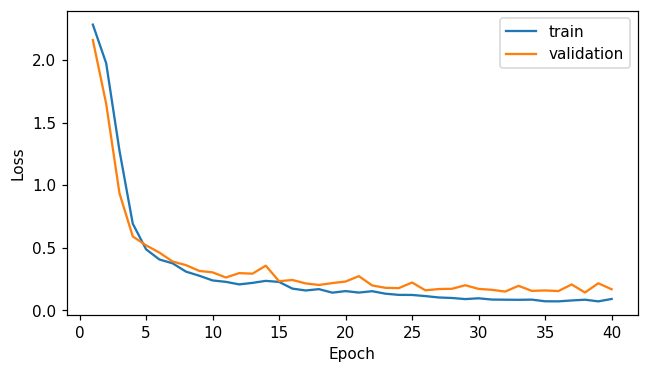

In [7]:
print(inspect.getsource(GridGCN))
model = GridGCN(adjacency)
assert model(data.train.tensors[0][:3]).shape == (3, 10)
history = Trainer(model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "loss.png")

## Ablation without neighbor edges

The self-loop-only model keeps the same learnable layers and input positions but removes neighbor mixing. Validation selects checkpoints for both. Their test comparison isolates this graph connectivity choice at the chosen training budget.

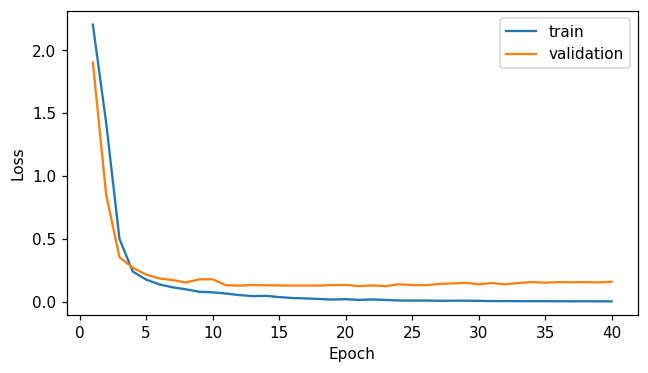

             graph  accuracy  macro_f1       nll
0       grid_edges  0.952778  0.952164  0.175602
1  self_loops_only  0.969444  0.969111  0.116992


In [9]:
seed_everything()
independent_model = GridGCN(torch.eye(64))
train_loader, validation_loader, test_loader = data.loaders()
history = Trainer(
    independent_model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS)
).fit(train_loader, validation_loader)
plot_history(history, output / "independent_loss.png")
rows = []
for name, candidate in [("grid_edges", model), ("self_loops_only", independent_model)]:
    logits, labels = predict(candidate, test_loader)
    rows.append({"graph": name, **classification_scores(logits, labels)})
print(pd.DataFrame(rows))
results = {"test": rows, "nodes": 64, "position_aware_readout": True}

## Reading the result

The flattened readout makes this an image-grid classifier using graph convolutions. It is useful for understanding aggregation, but does not claim invariance across arbitrary graph relabeling. Neighbor mixing can smooth both informative strokes and noise.

In [11]:
result_path = root / "results" / "07_graph_message_passing.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/07_graph_message_passing.json


## Next experiment

Replace the grid with superpixel graphs and use a permutation-invariant mean readout. Rebuild each graph from the image independently, then compare edge normalization and depth on validation data.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_4. [GCN](https://arxiv.org/abs/1609.02907).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.